# 91 The pilot events near the Gwangyang patch

The pilot ran the frozen detection chain (PhaseNet+ → PyOcto → HYPOINVERSE) on part of 2021 and 2026 while the full data were downloading. It covered 2021 days 1–64 and 184–245 (1 January – 5 March and 3 July – 2 September) and 2026 days 1–51 and 140–190 (1 January – 20 February and 20 May – 9 July). The relocation selection of stage G5 keeps **33 events**: within 5 km of the cluster centroid, at 10 km depth or deeper, with azimuthal gap < 180°, more than 7 phases, RMS < 1 s and HYPOINVERSE errors < 5 km.

This notebook shows what these 33 events are:
1. which are KMA-listed and which are new;
2. their locations and location quality, with the earlier precise relocation of the 11 KMA events for reference;
3. their picks;
4. their waveforms at the nearest stations, and how similar they are to the 2021 ML 2.2 (a test of whether they come from the same patch);
5. a relative magnitude from S-wave amplitude ratios, checked against the KMA magnitudes.

Caveats: these are **pilot** results. The locations are single-event HYPOINVERSE locations (plus a catalog-only double-difference relocation), not the final cross-correlation relocation. The pilot station table predates the freeze, so the KG stations are absent in 2026. The waveforms are the per-event exports of the pilot relocation run, with P and S picks in the SAC headers and R/T rotated with the dated orientation table.

In [1]:
import os, sys, re, glob, json, warnings
import numpy as np, pandas as pd
warnings.filterwarnings('ignore')
ROOT = '/home/msseo/works/73.Gwangyang_sequence'; P = f'{ROOT}/pilot'; RUN = f'{P}/relocation/hypodd_dl_pilot'; WF = f'{RUN}/waveforms_100km'
import pathlib
import matplotlib as mpl, matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib import font_manager as fm
from matplotlib.lines import Line2D
from obspy import read, UTCDateTime
pd.set_option('display.width', 230); pd.set_option('display.max_colwidth', 60); pd.set_option('display.max_rows', 100)
# Helvetica as in the Haenam and Imsil reports (pasted verbatim from notebooks/build_90_study_plan_report.py)
FONT_DIR = pathlib.Path.home() / ".local/share/fonts/helvetica-family"
USER_HELVETICA = pathlib.Path.home() / "Downloads/Helvetica/helvetica.ttf"
NIMBUS = "/usr/share/fonts/urw-base35/NimbusSans-{}.otf"
_REGULAR_SRC = (NIMBUS.format("Regular") if os.path.exists(NIMBUS.format("Regular"))
                else str(USER_HELVETICA))
SRC_REGULAR = pathlib.Path(_REGULAR_SRC)
_FACES = [
    (_REGULAR_SRC, "Helvetica-Regular.otf", "Regular", 400, False, False),
    (NIMBUS.format("Bold"), "Helvetica-Bold.otf", "Bold", 700, True, False),
    (NIMBUS.format("Italic"), "Helvetica-Italic.otf", "Italic", 400, False, True),
    (NIMBUS.format("BoldItalic"), "Helvetica-BoldItalic.otf", "Bold Italic", 700,
     True, True),
]
def _set_name(font, name_id, value):
    for rec in font["name"].names:
        if rec.nameID == name_id:
            rec.string = (value.encode("utf-16-be") if rec.platformID == 3
                          else value.encode("latin-1"))
def build_helvetica_family(force=False):
    have = [FONT_DIR / f[1] for f in _FACES]
    if not force and all(p.exists() for p in have):
        return True
    if not SRC_REGULAR.exists():
        return False
    from fontTools.ttLib import TTFont
    FONT_DIR.mkdir(parents=True, exist_ok=True)
    for src, outname, sub, wght, is_bold, is_ital in _FACES:
        if not os.path.exists(src):
            continue
        f = TTFont(src)
        full = "Helvetica" if sub == "Regular" else f"Helvetica {sub}"
        ps = "Helvetica" if sub == "Regular" else "Helvetica-" + sub.replace(" ", "")
        _set_name(f, 1, "Helvetica")
        _set_name(f, 2, sub)
        _set_name(f, 4, full)
        _set_name(f, 6, ps)
        _set_name(f, 16, "Helvetica")
        _set_name(f, 17, sub)
        os2 = f["OS/2"]
        os2.usWeightClass = wght
        fs = os2.fsSelection & ~(1 | (1 << 5) | (1 << 6))
        if is_ital:
            fs |= 1
        if is_bold:
            fs |= (1 << 5)
        if not is_bold and not is_ital:
            fs |= (1 << 6)
        os2.fsSelection = fs
        ms = f["head"].macStyle & ~3
        if is_bold:
            ms |= 1
        if is_ital:
            ms |= 2
        f["head"].macStyle = ms
        f.save(FONT_DIR / outname)
    return (FONT_DIR / _FACES[0][1]).exists()
def use_helvetica(verbose=False):
    ok = build_helvetica_family()
    if ok:
        for f in fm.findSystemFonts([str(FONT_DIR)]):
            fm.fontManager.addfont(f)
    have = {e.name for e in fm.fontManager.ttflist}
    fam = ["Helvetica", "Nimbus Sans", "DejaVu Sans"]
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": fam,
        "mathtext.fontset": "custom",
        "mathtext.rm": "Helvetica",
        "mathtext.it": "Helvetica:italic",
        "mathtext.bf": "Helvetica:bold",
        "mathtext.sf": "Helvetica",
        "mathtext.default": "regular",
        "axes.unicode_minus": False,
        "legend.framealpha": 1.0,
        "legend.facecolor": "white",
        "pdf.fonttype": 42,          # embed TrueType so vector output stays editable
        "ps.fonttype": 42,
        "svg.fonttype": "none",
    })
    resolved = "Helvetica" if "Helvetica" in have else (
        "Nimbus Sans" if "Nimbus Sans" in have else "DejaVu Sans")
    if verbose:
        n = len([e for e in fm.fontManager.ttflist if e.name == "Helvetica"])
        print(f"font family in use: {resolved} ({n} faces registered)")
    return resolved
DPI = 300
assert use_helvetica(verbose=True) == 'Helvetica'
plt.rcParams.update({"font.size": 8, "axes.labelsize": 8.5, "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 7.5, "axes.linewidth": 0.6,
                     "savefig.dpi": 200, "legend.framealpha": 1.0, "legend.edgecolor": "0.3", "legend.fancybox": False})
CEN = (35.0000, 127.7286)
def legend_above(fig, axes, handles, ncol, gap_pts=3, **kw):
    fig.canvas.draw(); r_ = fig.canvas.get_renderer()
    top = max(a.get_tightbbox(r_).y1 for a in axes) / fig.bbox.height
    return fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, top + gap_pts / 72 / fig.get_figheight()), ncol=ncol, frameon=True, **kw)
REP = f'{ROOT}/docs/reports/study_plan_20261015'; RFIG = f'{REP}/figures'; os.makedirs(RFIG, exist_ok=True)
def save_rep(fig, stem):   # the figures the study-plan report uses (PDF + PNG, 300 dpi)
    fig.savefig(f'{RFIG}/{stem}.pdf', bbox_inches='tight', pad_inches=0.03, facecolor='white')
    fig.savefig(f'{RFIG}/{stem}.png', bbox_inches='tight', pad_inches=0.03, facecolor='white', dpi=300)
C_SEQ, C_KMA, C_NEW = '#3b6fb6', '#8c6bb1', '#d1495b'
LAB = {'sequence': 'KMA-listed (sequence list)', 'kma_other': 'KMA-listed (not in the list)', 'new': 'Not in the KMA catalog'}
COL = {'sequence': C_SEQ, 'kma_other': C_KMA, 'new': C_NEW}

font family in use: Helvetica (4 faces registered)


## 1. The 33 events and their location quality

HYPOINVERSE locations in the Kim & Kim (1983) model. ERH and ERZ are HYPOINVERSE's horizontal and vertical error estimates (km); `num` is the number of phases used; `gap` the largest azimuthal gap between stations. P and S counts are the associated picks exported with each event.

In [2]:
sys.path.insert(0, f'{P}/detection/pipeline'); import config
from sumio import read_sum
man = pd.read_csv(f'{RUN}/event_manifest.csv', dtype={'event_id': str})
EVK = pd.read_csv(f'{ROOT}/registry/events.csv', parse_dates=['origin_time_utc'])
NEC = pd.read_csv(f'{ROOT}/data/catalogs/necis_events_domestic_1978_20261013.csv', encoding='utf-8-sig', parse_dates=['origin_utc'])
S = pd.concat([read_sum(f"{config.velmodel_dir('phasenet_plus', 'kim1983')}/{config.REGION_NAME}{y}.sum") for y in (2021, 2026)]); S = S[S.time.notna()].reset_index(drop=True)
rows = []
for r in man.itertuples():
    e = r.event_id; t = pd.Timestamp(f'{e[:4]}-{e[4:6]}-{e[6:8]} {e[8:10]}:{e[10:12]}:{e[12:14]}')
    h = S.iloc[(S.time - t).abs().values.argmin()]
    kseq = (EVK.origin_time_utc - h.time).abs().min() <= pd.Timedelta(seconds=3)
    n = NEC[(NEC.origin_utc - h.time).abs() <= pd.Timedelta(seconds=5)]
    pk = pd.read_csv(f'{WF}/{e}/{e}_picks.csv')
    rows.append(dict(event_id=e, cuspid=200000 + r.event_idx, time=h.time, lat=h.lat, lon=h.lon, depth=h.depth, num=int(h.num), gap=int(h.gap), rms=h.rms, erh=h.erh, erz=h.erz,
                     n_P=int((pk.phase == 'P').sum()), n_S=int((pk.phase == 'S').sum()), kma_ml=float(n.magnitude.iloc[0]) if len(n) else np.nan,
                     cls='sequence' if kseq else ('kma_other' if len(n) else 'new')))
E = pd.DataFrame(rows).sort_values('time').reset_index(drop=True)
E['dist_km'] = 111.2 * np.hypot(E.lat - CEN[0], (E.lon - CEN[1]) * np.cos(np.radians(CEN[0])))
E['kst'] = E.time + pd.Timedelta(hours=9)
E['n'] = np.arange(1, len(E) + 1)
print(E.cls.value_counts().rename(LAB).to_string())
display(E[['n', 'event_id', 'time', 'kst', 'lat', 'lon', 'depth', 'dist_km', 'num', 'n_P', 'n_S', 'gap', 'rms', 'erh', 'erz', 'kma_ml', 'cls']].round({'dist_km': 2}))

cls
Not in the KMA catalog          21
KMA-listed (sequence list)      11
KMA-listed (not in the list)     1


,n,event_id,time,kst,lat,lon,depth,dist_km,num,n_P,n_S,gap,rms,erh,erz,kma_ml,cls
0,1,20210718145001,2021-07-18 14:50:01.270,2021-07-18 23:50:01.270,34.9978,127.7280,14.21,0.25,15,5,10,86,0.20,0.5,0.7,NaN,new
1,2,20210719025611,2021-07-19 02:56:11.010,2021-07-19 11:56:11.010,34.9935,127.7205,12.71,1.03,9,3,6,111,0.16,0.6,1.4,NaN,new
2,3,20210719033812,2021-07-19 03:38:12.690,2021-07-19 12:38:12.690,34.9997,127.7243,13.85,0.39,12,4,9,109,0.18,0.5,0.9,NaN,new
3,4,20210720161418,2021-07-20 16:14:18.820,2021-07-21 01:14:18.820,34.9996,127.7278,14.63,0.09,86,43,44,35,0.20,0.2,0.3,1.3,sequence
4,5,20210720172705,2021-07-20 17:27:05.310,2021-07-21 02:27:05.310,34.9949,127.7221,12.44,0.82,16,7,9,103,0.15,0.5,1.0,NaN,new
5,6,20210826095443,2021-08-26 09:54:43.120,2021-08-26 18:54:43.120,35.0016,127.7276,14.49,0.20,43,17,27,40,0.24,0.3,0.4,NaN,new
6,7,20210826100025,2021-08-26 10:00:25.660,2021-08-26 19:00:25.660,34.9976,127.7301,13.17,0.30,19,7,12,86,0.23,0.4,1.3,NaN,new
7,8,20210826101018,2021-08-26 10:10:18.360,2021-08-26 19:10:18.360,35.0038,127.7286,14.98,0.42,10,3,7,86,0.21,0.6,0.7,NaN,new
8,9,20210827002315,2021-08-27 00:23:15.490,2021-08-27 09:23:15.490,35.0012,127.7274,14.76,0.17,114,57,57,35,0.18,0.2,0.2,1.6,sequence
9,10,20210827002542,2021-08-27 00:25:42.780,2021-08-27 09:25:42.780,34.9938,127.7292,14.08,0.69,12,4,8,112,0.26,0.6,0.8,NaN,new


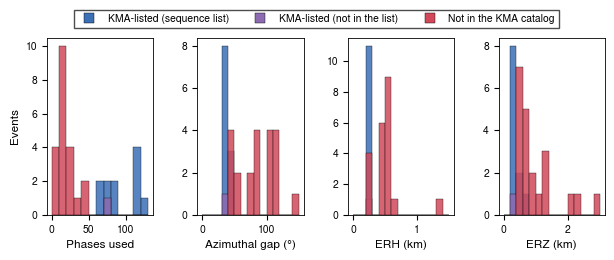

medians by class:


,num,gap,erh,erz,depth,dist_km
cls,,,,,,
KMA-listed (not in the list),77.0,35.0,0.2,0.3,14.71,0.13
Not in the KMA catalog,16.0,86.0,0.5,0.7,14.08,0.39
KMA-listed (sequence list),86.0,35.0,0.2,0.3,14.77,0.09


In [3]:
fig, axs = plt.subplots(1, 4, figsize=(7.2, 2.3), gridspec_kw=dict(wspace=0.42))
for ax, col, lab, bins in ((axs[0], 'num', 'Phases used', np.arange(0, 135, 10)), (axs[1], 'gap', 'Azimuthal gap (°)', np.arange(0, 160, 10)),
                           (axs[2], 'erh', 'ERH (km)', np.arange(0, 1.6, 0.1)), (axs[3], 'erz', 'ERZ (km)', np.arange(0, 3.2, 0.2))):
    for c in ('sequence', 'kma_other', 'new'):
        v = E[E.cls == c][col]
        if len(v): ax.hist(v, bins=bins, color=COL[c], alpha=0.85, edgecolor='k', linewidth=0.3, label=LAB[c], histtype='bar', stacked=False)
    ax.set_xlabel(lab)
axs[0].set_ylabel('Events')
handles = [Line2D([], [], marker='s', ls='', ms=7, mfc=COL[c], mec='k', mew=0.3, label=LAB[c]) for c in COL]
legend_above(fig, axs, handles, 3)
plt.show()
q = E.groupby('cls')[['num', 'gap', 'erh', 'erz', 'depth', 'dist_km']].median().rename(index=LAB); print('medians by class:'); display(q.round(2))

## 2. Locations

**Relative view.** (a) Map view and (b, c) depth sections of the HYPOINVERSE locations in km from the cluster centroid, with HYPOINVERSE error bars (ERH horizontally, ERZ vertically). Black crosses: the earlier precise relocation of the 11 KMA events (`gwangyang_pnplus`: cross-correlation double difference, bootstrap 95% half-widths of a few metres). (d) The catalog-only double-difference relocation of the pilot run (picks only, no cross-correlation, no bootstrap), positions relative to its mean.

**Absolute view.** The same HYPOINVERSE locations in longitude, latitude and depth, each with its HYPOINVERSE 1σ error ellipse. HYPOINVERSE gives three principal error axes per event (azimuth, dip and size, in the header lines of its archive file `.arc`); the ellipse is that error ellipsoid projected exactly onto each plane. Panel (d) zooms on the patch.

catalog-only relocation: 31 of 33 events; missing: 20210827002542, 20210827020929


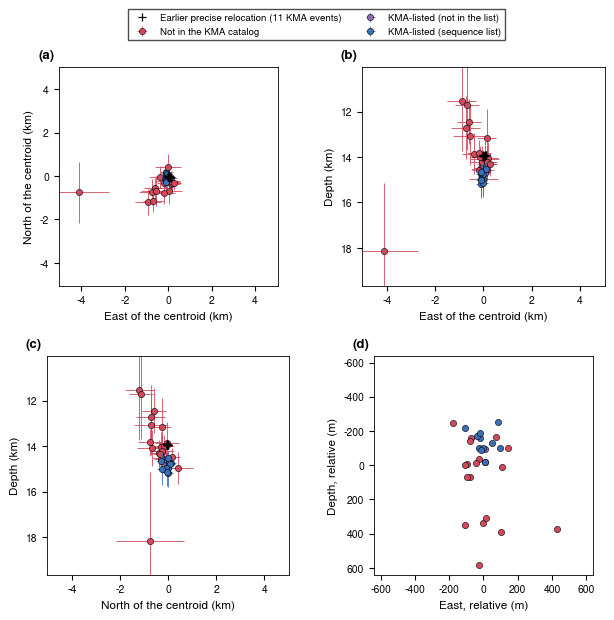

catalog-only relocation spread (std): east 110 m, north 188 m, depth 214 m; HYPOINVERSE spread: east 749 m, north 366 m, depth 1165 m


In [4]:
PREV = pd.read_csv('/home/msseo/works/10.Earthquake_cycle_project/pipeline/runs/gwangyang_pnplus/2.HypoDD/02.dt.cc/final_locations.csv', dtype={'event_id': str})
km_lon = 111.19 * np.cos(np.radians(CEN[0])); km_lat = 111.19
E['x'] = (E.lon - CEN[1]) * km_lon; E['y'] = (E.lat - CEN[0]) * km_lat
PREV['x'] = (PREV.longitude - CEN[1]) * km_lon; PREV['y'] = (PREV.latitude - CEN[0]) * km_lat
cols = ['ID', 'LAT', 'LON', 'DEPTH', 'X', 'Y', 'Z', 'EX', 'EY', 'EZ', 'YR', 'MO', 'DY', 'HR', 'MI', 'SC', 'MAG', 'NCCP', 'NCCS', 'NCTP', 'NCTS', 'RCC', 'RCT', 'CID']
DD = pd.read_csv(f'{RUN}/2.HypoDD/01.dt.ct/hypoDD.reloc', sep=r'\s+', header=None, names=cols).merge(E[['cuspid', 'event_id', 'cls', 'n']], left_on='ID', right_on='cuspid')
print(f'catalog-only relocation: {len(DD)} of {len(E)} events; missing: ' + ', '.join(E.event_id[~E.cuspid.isin(DD.ID)]))
order = ('new', 'kma_other', 'sequence')
fig = plt.figure(figsize=(7.2, 6.6)); gs = fig.add_gridspec(2, 2, hspace=0.32, wspace=0.3)
ax, bx, cx, dx = (fig.add_subplot(gs[i, j]) for i, j in ((0, 0), (0, 1), (1, 0), (1, 1)))
for c in order:
    s = E[E.cls == c]; z = 3 if c != 'new' else 2
    ax.errorbar(s.x, s.y, xerr=s.erh, yerr=s.erh, fmt='o', ms=4.5, color=COL[c], mec='k', mew=0.4, elinewidth=0.6, capsize=0, label=LAB[c], zorder=z)
    bx.errorbar(s.x, s.depth, xerr=s.erh, yerr=s.erz, fmt='o', ms=4.5, color=COL[c], mec='k', mew=0.4, elinewidth=0.6, capsize=0, zorder=z)
    cx.errorbar(s.y, s.depth, xerr=s.erh, yerr=s.erz, fmt='o', ms=4.5, color=COL[c], mec='k', mew=0.4, elinewidth=0.6, capsize=0, zorder=z)
for a_, xx, yy in ((ax, PREV.x, PREV.y), (bx, PREV.x, PREV.depth_km), (cx, PREV.y, PREV.depth_km)):
    a_.plot(xx, yy, '+', color='k', ms=6, mew=0.9, zorder=4, label='Earlier precise relocation (11 KMA events)' if a_ is ax else None)
ax.set_xlabel('East of the centroid (km)'); ax.set_ylabel('North of the centroid (km)'); ax.set_aspect('equal')
bx.set_xlabel('East of the centroid (km)'); bx.set_ylabel('Depth (km)'); cx.set_xlabel('North of the centroid (km)'); cx.set_ylabel('Depth (km)')
lim = 1.15 * max(E.x.abs().max(), E.y.abs().max()) + 0.3
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); bx.set_xlim(-lim, lim); cx.set_xlim(-lim, lim)
for a_ in (bx, cx): a_.set_ylim(E.depth.max() + 1.5, E.depth.min() - 1.5)
x0, y0, z0 = DD.X.mean(), DD.Y.mean(), DD.Z.mean()
for c in order:
    s = DD[DD.cls == c]; dx.plot(s.X - x0, s.Z - z0, 'o', ms=4.5, color=COL[c], mec='k', mew=0.4, zorder=3)
dx.set_xlabel('East, relative (m)'); dx.set_ylabel('Depth, relative (m)'); dx.set_aspect('equal')
lm = 1.1 * max((DD.X - x0).abs().max(), (DD.Z - z0).abs().max()); dx.set_xlim(-lm, lm); dx.set_ylim(lm, -lm)
for a_, l_ in zip((ax, bx, cx, dx), 'abcd'): a_.annotate(f'({l_})', xy=(-0.02, 1.0), xycoords='axes fraction', xytext=(0, 4), textcoords='offset points', ha='right', va='bottom', fontsize=9.5, fontweight='bold')
h_, l_ = ax.get_legend_handles_labels(); legend_above(fig, (ax, bx), h_, 2, fontsize=7)
save_rep(fig, 'Figure_07_pilot_locations_relative')
plt.show()
print(f'catalog-only relocation spread (std): east {(DD.X - x0).std():.0f} m, north {(DD.Y - y0).std():.0f} m, depth {(DD.Z - z0).std():.0f} m; HYPOINVERSE spread: east {E.x.std() * 1000:.0f} m, north {E.y.std() * 1000:.0f} m, depth {E.depth.std() * 1000:.0f} m')

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


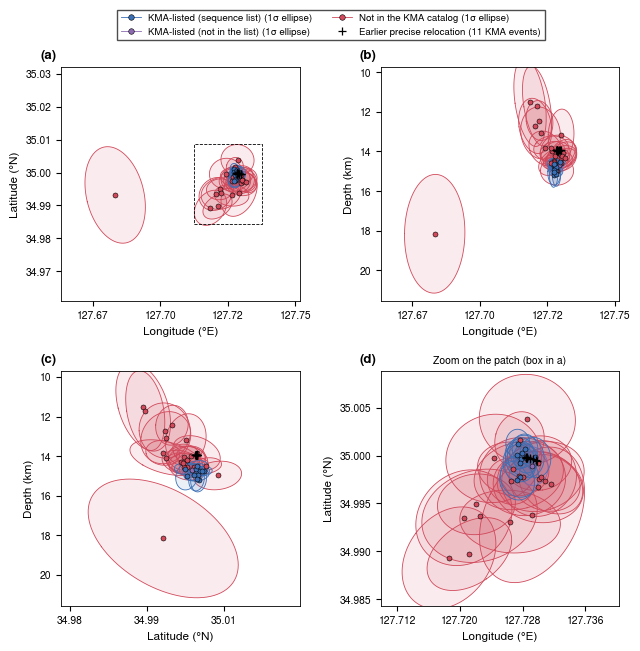

largest principal 1σ error per class (median, km): {'KMA-listed (not in the list)': 0.29, 'Not in the KMA catalog': 0.73, 'KMA-listed (sequence list)': 0.29}


In [5]:
def arc_headers(path):
    out = []
    for L in open(path):
        if len(L) < 120 or not L[:4].isdigit(): continue
        c = lambda a, b: L[a - 1:b]
        f = lambda a, b, s=1.0: float(c(a, b)) * s if c(a, b).strip() else np.nan
        t = pd.Timestamp(f'{c(1, 4)}-{c(5, 6)}-{c(7, 8)} {c(9, 10)}:{c(11, 12)}') + pd.Timedelta(seconds=f(13, 16, 0.01))
        lat = f(17, 18) + f(20, 23, 0.01) / 60 * (-1 if c(19, 19) == 'S' else 1); lon = f(24, 26) + f(28, 31, 0.01) / 60 * (-1 if c(27, 27) == 'W' else 1)
        out.append(dict(time=t, lat=lat, lon=lon, depth=f(32, 36, 0.01), az1=f(53, 55), dip1=f(56, 57), s1=f(58, 61, 0.01), az2=f(62, 64), dip2=f(65, 66), s2=f(67, 70, 0.01),
                        s3=f(77, 80, 0.01), erh_arc=f(86, 89, 0.01), erz_arc=f(90, 93, 0.01)))
    return pd.DataFrame(out)
ARC = pd.concat([arc_headers(f"{config.velmodel_dir('phasenet_plus', 'kim1983')}/{config.REGION_NAME}{y}.arc") for y in (2021, 2026)], ignore_index=True)
idx = [int((ARC.time - t).abs().values.argmin()) for t in E.time]
A = ARC.iloc[idx].reset_index(drop=True)
assert ((A.time.values - E.time.values) / np.timedelta64(1, 's') < 0.02).all() and np.allclose(A.erh_arc, E.erh, atol=0.051) and np.allclose(A.erz_arc, E.erz, atol=0.051), 'archive headers match the summary'
def unit(az, dip):
    a, d = np.radians(az), np.radians(dip); return np.array([np.sin(a) * np.cos(d), np.cos(a) * np.cos(d), np.sin(d)])   # east, north, down
def cov(r):
    v1, v2 = unit(r.az1, r.dip1), unit(r.az2, r.dip2); v3 = np.cross(v1, v2); v3 /= np.linalg.norm(v3)
    return sum(s ** 2 * np.outer(v, v) for s, v in ((r.s1, v1), (r.s2, v2), (r.s3, v3)))
def ellipse(C2, n=100):
    w, V = np.linalg.eigh(C2); t = np.linspace(0, 2 * np.pi, n)
    return V @ (np.sqrt(np.maximum(w, 0))[:, None] * np.vstack([np.cos(t), np.sin(t)]))
def draw(a_, which):
    for c in order:
        for i in E.index[E.cls == c]:
            r, C = E.loc[i], cov(A.loc[i]); z = 3 if c != 'new' else 2
            if which == 'map': e_ = ellipse(C[np.ix_([0, 1], [0, 1])]); X, Y = r.lon + e_[0] / km_lon, r.lat + e_[1] / km_lat
            elif which == 'lon': e_ = ellipse(C[np.ix_([0, 2], [0, 2])]); X, Y = r.lon + e_[0] / km_lon, r.depth + e_[1]
            else: e_ = ellipse(C[np.ix_([1, 2], [1, 2])]); X, Y = r.lat + e_[0] / km_lat, r.depth + e_[1]
            a_.fill(X, Y, color=COL[c], alpha=0.10, lw=0, zorder=z); a_.plot(X, Y, color=COL[c], lw=0.6, zorder=z)
        s = E[E.cls == c]
        xx, yy = {'map': (s.lon, s.lat), 'lon': (s.lon, s.depth), 'lat': (s.lat, s.depth)}[which]
        a_.plot(xx, yy, 'o', ms=3.6, color=COL[c], mec='k', mew=0.4, zorder=4)
    xx, yy = {'map': (PREV.longitude, PREV.latitude), 'lon': (PREV.longitude, PREV.depth_km), 'lat': (PREV.latitude, PREV.depth_km)}[which]
    a_.plot(xx, yy, '+', color='k', ms=6, mew=0.9, zorder=5)
fig = plt.figure(figsize=(7.2, 7.0)); gs = fig.add_gridspec(2, 2, hspace=0.3, wspace=0.34)
ax, bx, cx, dx = (fig.add_subplot(gs[i, j]) for i, j in ((0, 0), (0, 1), (1, 0), (1, 1)))
draw(ax, 'map'); draw(bx, 'lon'); draw(cx, 'lat'); draw(dx, 'map')
ax.set_xlabel('Longitude (°E)'); ax.set_ylabel('Latitude (°N)'); bx.set_xlabel('Longitude (°E)'); bx.set_ylabel('Depth (km)'); cx.set_xlabel('Latitude (°N)'); cx.set_ylabel('Depth (km)')
pad = 0.008; xl = (E.lon.min() - pad - 0.012, E.lon.max() + pad + 0.012); yl = (E.lat.min() - pad - 0.008, E.lat.max() + pad + 0.008)
ax.set_xlim(*xl); ax.set_ylim(*yl); bx.set_xlim(*xl); cx.set_xlim(*yl)
ax.set_aspect(1 / np.cos(np.radians(CEN[0])), adjustable='datalim')
for a_ in (bx, cx): a_.set_ylim(E.depth.max() + 3.4, E.depth.min() - 1.8)
core = E[E.dist_km <= 2.0]; zx = (core.lon.min() - 0.006, core.lon.max() + 0.006); zy = (core.lat.min() - 0.005, core.lat.max() + 0.005)
dx.set_xlim(*zx); dx.set_ylim(*zy); dx.set_aspect(1 / np.cos(np.radians(CEN[0])), adjustable='datalim'); dx.set_xlabel('Longitude (°E)'); dx.set_ylabel('Latitude (°N)')
ax.plot([zx[0], zx[1], zx[1], zx[0], zx[0]], [zy[0], zy[0], zy[1], zy[1], zy[0]], color='k', lw=0.6, ls='--', zorder=6)
for a_ in (ax, bx, cx, dx): a_.xaxis.set_major_locator(mpl.ticker.MaxNLocator(4)); a_.xaxis.set_major_formatter(mpl.ticker.FormatStrFormatter('%.2f' if a_ is not dx else '%.3f'))
for a_ in (ax, dx): a_.yaxis.set_major_formatter(mpl.ticker.FormatStrFormatter('%.2f' if a_ is ax else '%.3f'))
for a_, l_ in zip((ax, bx, cx, dx), 'abcd'): a_.annotate(f'({l_})', xy=(-0.02, 1.0), xycoords='axes fraction', xytext=(0, 4), textcoords='offset points', ha='right', va='bottom', fontsize=9.5, fontweight='bold')
dx.set_title('Zoom on the patch (box in a)', fontsize=7.5)
handles = [Line2D([], [], marker='o', ls='-', lw=0.6, ms=4, color=COL[c], mec='k', mew=0.4, label=LAB[c] + ' (1σ ellipse)') for c in ('sequence', 'kma_other', 'new')] + \
          [Line2D([], [], marker='+', ls='', ms=6, mew=0.9, color='k', label='Earlier precise relocation (11 KMA events)')]
legend_above(fig, (ax, bx), handles, 2, fontsize=7)
save_rep(fig, 'Figure_08_pilot_locations_absolute')
plt.show()
print('largest principal 1σ error per class (median, km):', E.assign(s1=A.s1).groupby('cls').s1.median().rename(index=LAB).round(2).to_dict())

## 3. Waveforms and picks at the nearest stations

Records filtered 5–20 Hz and normalized. The vertical (Z) panels are aligned on each event's own P pick at that station, the transverse (T) panels on its own S pick. Where an event has no pick of that phase at the station, the trace is aligned through its other pick and the station's median S−P interval of the KMA events, and drawn lighter with an open marker at time zero. A tick marks the event's other pick (S on the P-aligned panels, P on the S-aligned panels), so the S−P interval of every event can be read off directly. GWYB is 7 km from the cluster; BAU 17 km.

KS.GWYB: median S-P of the KMA events 1.64 s (n 12)
KS.BAU: median S-P of the KMA events 2.53 s (n 12)


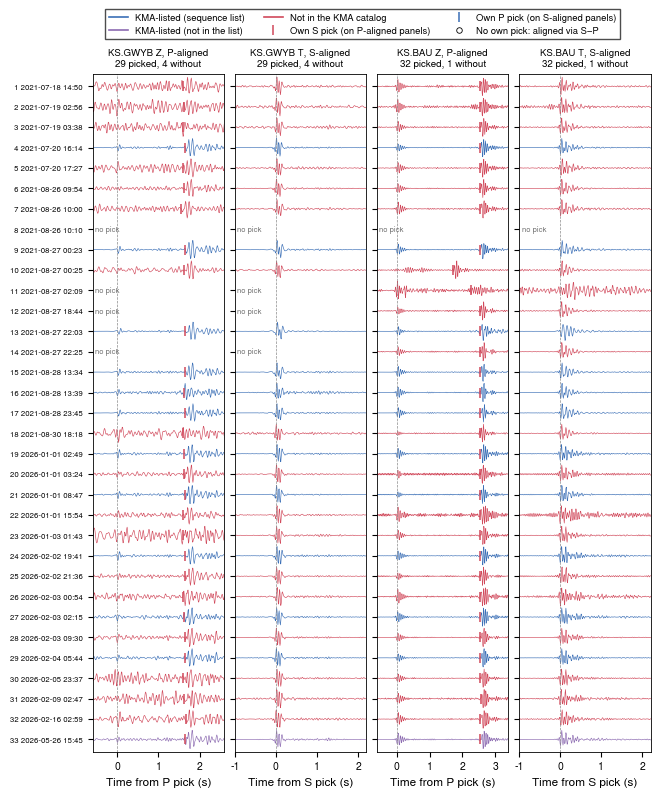

In [6]:
def load(e, net, sta, comp):
    f = glob.glob(f'{WF}/{e}/{e}.{net}.{sta}.??{comp}.sac')
    if not f: return None
    tr = read(f[0])[0]; h = tr.stats.sac; ref = tr.stats.starttime - h.b
    p = ref + float(h.a) if 'a' in h and h.a > -1e4 else None; s = ref + float(h.t0) if 't0' in h and h.t0 > -1e4 else None
    tr.detrend('demean'); tr.taper(0.05); return tr, p, s
def utc(t): return UTCDateTime(pd.Timestamp(t).to_pydatetime())
def picks(e, net, sta):
    g = load(e, net, sta, 'Z'); return (g[1], g[2]) if g else (None, None)
SPMED = {}
for sta in ('GWYB', 'BAU'):
    sp = [s - p for r in E[E.cls != 'new'].itertuples() for p, s in [picks(r.event_id, 'KS', sta)] if p and s]
    SPMED[sta] = float(np.median(sp)); print(f'KS.{sta}: median S-P of the KMA events {SPMED[sta]:.2f} s (n {len(sp)})')
fig, axs = plt.subplots(1, 4, figsize=(7.2, 8.8), sharey=True, gridspec_kw=dict(wspace=0.08))
for k, (sta, comp, phase, pre, post) in enumerate((('GWYB', 'Z', 'P', 0.6, 2.6), ('GWYB', 'T', 'S', 1.0, 2.2), ('BAU', 'Z', 'P', 0.6, 3.4), ('BAU', 'T', 'S', 1.0, 2.2))):
    ax = axs[k]; n_own = n_alt = n_none = 0
    for i, r in E.iterrows():
        g = load(r.event_id, 'KS', sta, comp); p, s = picks(r.event_id, 'KS', sta)
        if g is None: continue
        own = p if phase == 'P' else s
        alt = (s - SPMED[sta] if s else None) if phase == 'P' else (p + SPMED[sta] if p else None)
        t0 = own if own is not None else alt
        if t0 is None:
            ax.text(0.02, i, 'no pick', transform=ax.get_yaxis_transform(), ha='left', va='center', fontsize=5.6, color='0.45'); n_none = locals().get('n_none', 0) + 1; continue
        tr = g[0].copy(); tr.filter('bandpass', freqmin=5, freqmax=20, corners=4, zerophase=True)
        w = tr.slice(t0 - pre, t0 + post)
        if not len(w.data): continue
        x = w.times() + (w.stats.starttime - t0); y = w.data / (np.abs(w.data).max() + 1e-20)
        ax.plot(x, i + 0.45 * y, color=COL[r.cls], lw=0.45, alpha=1.0 if own is not None else 0.45)
        if own is not None: n_own += 1
        else: n_alt += 1; ax.plot(0, i, 'o', ms=3.2, mfc='white', mec='k', mew=0.6, zorder=5)
        other = s if phase == 'P' else p
        if other is not None and -pre <= other - t0 <= post: ax.plot(other - t0, i, '|', ms=7, mew=1.1, color=C_NEW if phase == 'P' else C_SEQ, zorder=5)
    ax.axvline(0, color='0.55', lw=0.5, ls='--')
    ax.set_xlim(-pre, post); ax.set_xlabel(f'Time from {phase} pick (s)'); ax.set_title(f'KS.{sta} {comp}, {phase}-aligned\n{n_own} picked' + (f', {n_alt} via S−P' if n_alt else '') + f', {n_none} without', fontsize=7.0)
axs[0].set_yticks(range(len(E))); axs[0].set_yticklabels([f'{r.n:2d} {r.time:%Y-%m-%d %H:%M}' for r in E.itertuples()], fontsize=5.6)
axs[0].set_ylim(len(E) - 0.4, -0.6)
handles = [Line2D([], [], color=COL[c], lw=1.2, label=LAB[c]) for c in COL] + \
          [Line2D([], [], color=C_NEW, marker='|', ls='', ms=7, mew=1.1, label='Own S pick (on P-aligned panels)'), Line2D([], [], color=C_SEQ, marker='|', ls='', ms=7, mew=1.1, label='Own P pick (on S-aligned panels)'),
           Line2D([], [], marker='o', ls='', ms=4, mfc='white', mec='k', mew=0.6, label='No own pick: aligned via S−P')]
legend_above(fig, axs, handles, 3, fontsize=6.8)
save_rep(fig, 'Figure_09_pilot_waveforms')
plt.show()

## 4. Are the new events on the same patch?

Two tests that do not depend on the HYPOINVERSE locations:
- **S−P intervals.** At a given station, events at the same place have the same S−P interval. For every station where an event has both a P and an S pick, the interval is compared with the median interval of the KMA-listed events at that station. At 15–30 km, 0.1 s of S−P is about 0.8 km of distance.
- **Waveform similarity, counted only where the event has signal.** Normalized cross-correlation with the ML 2.2 (2021-08-27 22:03:23 UTC) at the same station, 5–20 Hz (the relocation band): P from 0.3 s before to 1.2 s after the median P time on Z, S from 0.3 s before to 1.7 s after the median S time on T, maximum over lags of ±0.3 s. A station counts for an event only where that event's window peak is at least 4 times the peak of its own pre-P noise (3.3–0.7 s before the median P). The **noise baseline** is the same correlation computed between the ML 2.2 window and each event's noise window: what correlation looks like without a signal.

stations considered (within 40 km): GWYB (7 km), PHDA (14 km), GMNA (15 km), BAU (17 km), JRB (25 km), HWJA (26 km), NAHA (27 km), BLLA (28 km), YESA (29 km), SCYA (31 km), GURA (32 km), SCHA (33 km), JINA (34 km), WDL (34 km), GSU (38 km), GRE (39 km)
noise baseline (95th percentile of CC without signal): P 0.46, S 0.41; station-phase pairs with SNR >= 4: 251 of 599


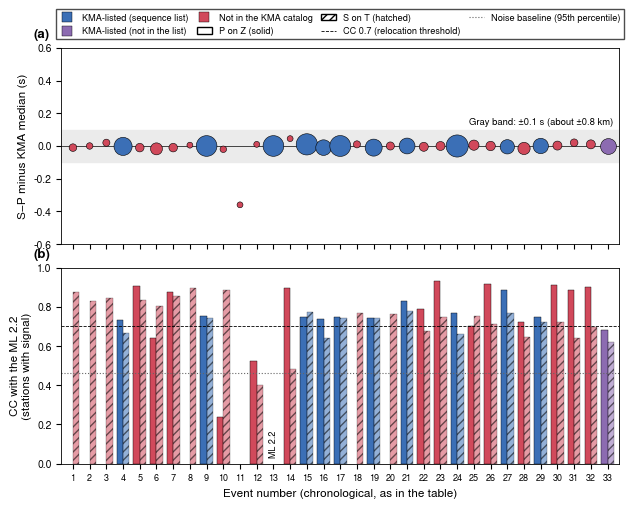

,n,event_id,cls,num,erz,depth,dist_km,dsp_med,dsp_n,cc_P,n_cc_P,cc_S,n_cc_S
0,1,20210718145001,new,15,0.7,14.21,0.25,-0.01,5,NaN,NaN,0.88,3.0
1,2,20210719025611,new,9,1.4,12.71,1.03,-0.00,3,NaN,NaN,0.83,4.0
2,3,20210719033812,new,12,0.9,13.85,0.39,0.02,4,NaN,NaN,0.84,3.0
3,4,20210720161418,sequence,86,0.3,14.63,0.09,-0.00,40,0.73,7.0,0.66,11.0
4,5,20210720172705,new,16,1.0,12.44,0.82,-0.01,7,0.91,1.0,0.83,4.0
5,6,20210826095443,new,43,0.4,14.49,0.20,-0.02,16,0.64,3.0,0.81,6.0
6,7,20210826100025,new,19,1.3,13.17,0.30,-0.01,7,0.88,1.0,0.86,4.0
7,8,20210826101018,new,10,0.7,14.98,0.42,0.01,2,NaN,NaN,0.90,3.0
8,9,20210827002315,sequence,114,0.2,14.76,0.17,0.00,53,0.75,11.0,0.74,12.0
9,10,20210827002542,new,12,0.8,14.08,0.69,-0.02,3,0.24,1.0,0.89,3.0


In [7]:
REF = E.event_id[(E.time - pd.Timestamp('2021-08-27 22:03:22')).abs().idxmin()]
TIME = E.set_index('event_id').time
stas = pd.read_csv(f'{P}/detection/station_table/stations.csv')
stas['dist_km'] = 111.2 * np.hypot(stas.Latitude - CEN[0], (stas.Longitude - CEN[1]) * np.cos(np.radians(CEN[0])))
# picks of every event and station, from the SAC headers
PK = []
for r in E.itertuples():
    for f in glob.glob(f'{WF}/{r.event_id}/{r.event_id}.*.??Z.sac'):
        net, sta = os.path.basename(f).split('.')[1:3]
        g = load(r.event_id, net, sta, 'Z')
        if g is None: continue
        PK.append(dict(event_id=r.event_id, n=r.n, cls=r.cls, net=net, sta=sta, p=(g[1] - utc(r.time)) if g[1] else np.nan, s=(g[2] - utc(r.time)) if g[2] else np.nan))
PK = pd.DataFrame(PK).merge(stas[['Network', 'Code', 'dist_km']], left_on=['net', 'sta'], right_on=['Network', 'Code'])
PK['sp'] = PK.s - PK.p
refsp = PK[PK.cls != 'new'].dropna(subset=['sp']).groupby('sta').sp.median()
PK['dsp'] = PK.sp - PK.sta.map(refsp)
dsp = PK.dropna(subset=['dsp']).groupby('event_id').agg(dsp_med=('dsp', 'median'), dsp_n=('dsp', 'size'))
E = E.drop(columns=[c for c in ('dsp_med', 'dsp_n') if c in E]).merge(dsp, left_on='event_id', right_index=True, how='left')
def window(e, net, sta, comp, t_rel, pre, post):
    g = load(e, net, sta, comp)
    if g is None: return None
    tr = g[0].copy(); tr.filter('bandpass', freqmin=5, freqmax=20, corners=4, zerophase=True)
    t0 = utc(TIME[e]) + t_rel
    w = tr.slice(t0 - pre - 0.3, t0 + post + 0.3).data.astype(float)
    return w if len(w) > int((pre + post) * 100) else None
def ccmax(a, b, lag=30):
    n = min(len(a), len(b)); a, b = a[:n], b[:n]; bb = b[lag:n - lag]; best = -1.0
    for k in range(-lag, lag + 1):
        aa = a[lag + k:n - lag + k]; d = np.sqrt((aa ** 2).sum() * (bb ** 2).sum())
        if d > 0: best = max(best, float((aa * bb).sum() / d))
    return best
near = stas[stas.dist_km <= 40]
tt = {}
for s in near.itertuples():
    q = PK[(PK.sta == s.Code)]
    if q.p.notna().sum() >= 3 and q.s.notna().sum() >= 3: tt[(s.Network, s.Code)] = (float(q.p.median()), float(q.s.median()), s.dist_km)
CC, NOISE = [], []
for r in E.itertuples():
    for (net, sta), (tp, ts, dk) in tt.items():
        nz = window(r.event_id, net, sta, 'Z', tp - 2.0, 1.0, 1.0)                 # noise window 3.3-0.7 s before the median P, as long as the S window
        nt = window(r.event_id, net, sta, 'T', tp - 2.0, 1.0, 1.0)
        for ph, comp, trel, pre, post, nw in (('P', 'Z', tp, 0.3, 1.2, nz), ('S', 'T', ts, 0.3, 1.7, nt)):
            a = window(r.event_id, net, sta, comp, trel, pre, post); b = window(REF, net, sta, comp, trel, pre, post)
            if a is None or b is None or nw is None: continue
            snr = np.abs(a[30:-30]).max() / (np.abs(nw[30:-30]).max() + 1e-30)
            if r.event_id != REF:
                CC.append(dict(event_id=r.event_id, n=r.n, sta=sta, dist_km=dk, phase=ph, snr=snr, cc=ccmax(a, b)))
                bn = nw[:len(b)] if len(nw) >= len(b) else None
                if bn is not None: NOISE.append(dict(phase=ph, cc=ccmax(bn, b)))
CC = pd.DataFrame(CC); NOISE = pd.DataFrame(NOISE)
n95 = NOISE.groupby('phase').cc.quantile(0.95).to_dict()
good = CC[CC.snr >= 4]
med = good.groupby(['event_id', 'phase']).cc.median().unstack(); nst = good.groupby(['event_id', 'phase']).sta.nunique().unstack()
E = E.drop(columns=[c for c in ('cc_P', 'cc_S', 'n_cc_P', 'n_cc_S') if c in E])
E = E.merge(med.rename(columns={'P': 'cc_P', 'S': 'cc_S'}), left_on='event_id', right_index=True, how='left').merge(nst.rename(columns={'P': 'n_cc_P', 'S': 'n_cc_S'}), left_on='event_id', right_index=True, how='left')
print('stations considered (within 40 km):', ', '.join(f'{k[1]} ({v[2]:.0f} km)' for k, v in tt.items()))
print(f"noise baseline (95th percentile of CC without signal): P {n95['P']:.2f}, S {n95['S']:.2f}; station-phase pairs with SNR >= 4: {len(good)} of {len(CC)}")
fig, (ax, bx) = plt.subplots(2, 1, figsize=(7.2, 5.4), sharex=True, gridspec_kw=dict(hspace=0.12))
x = np.arange(len(E)); w_ = 0.38
ax.axhspan(-0.1, 0.1, color='0.92', zorder=0)
ax.errorbar(x, E.dsp_med, fmt='none', ecolor='0.5', elinewidth=0.5)
for c in COL:
    s = E[E.cls == c]; ax.scatter(s.n - 1, s.dsp_med, s=10 + 4 * s.dsp_n.fillna(0), color=COL[c], edgecolor='k', linewidth=0.4, zorder=3)
ax.axhline(0, color='k', lw=0.5); ax.set_ylabel('S−P minus KMA median (s)'); ax.set_ylim(-0.6, 0.6)
ax.text(0.99, 0.60, 'Gray band: ±0.1 s (about ±0.8 km)', transform=ax.transAxes, ha='right', va='bottom', fontsize=6.8)
bx.bar(x - w_ / 2, E.cc_P, width=w_, color=[COL[c] for c in E.cls], edgecolor='k', linewidth=0.3)
bx.bar(x + w_ / 2, E.cc_S, width=w_, color=[COL[c] for c in E.cls], edgecolor='k', linewidth=0.3, alpha=0.55, hatch='////')
bx.axhline(0.7, color='k', lw=0.6, ls='--'); bx.axhline(max(n95.values()), color='0.4', lw=0.8, ls=':')
bx.set_ylim(0, 1.0); bx.set_ylabel('CC with the ML 2.2\n(stations with signal)')
bx.set_xticks(x); bx.set_xticklabels([str(n) for n in E.n], fontsize=6.5); bx.set_xlabel('Event number (chronological, as in the table)'); bx.set_xlim(-0.7, len(E) - 0.3)
iref = int(E.n[E.event_id == REF].iloc[0]) - 1; bx.text(iref, 0.03, 'ML 2.2', rotation=90, ha='center', va='bottom', fontsize=6.5)
handles = [Line2D([], [], marker='s', ls='', ms=7, mfc=COL[c], mec='k', mew=0.3, label=LAB[c]) for c in COL] + \
          [mpl.patches.Patch(fc='white', ec='k', label='P on Z (solid)'), mpl.patches.Patch(fc='white', ec='k', hatch='////', label='S on T (hatched)'),
           Line2D([], [], color='k', lw=0.6, ls='--', label='CC 0.7 (relocation threshold)'), Line2D([], [], color='0.4', lw=0.8, ls=':', label='Noise baseline (95th percentile)')]
ax.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=4, frameon=True, fontsize=6.6, columnspacing=0.9, handlelength=1.6)
for a_, l_ in zip((ax, bx), 'ab'): a_.annotate(f'({l_})', xy=(-0.02, 1.0), xycoords='axes fraction', xytext=(0, 5), textcoords='offset points', ha='right', va='bottom', fontsize=9.5, fontweight='bold')
save_rep(fig, 'Figure_10_pilot_same_patch')
plt.show()
display(E[['n', 'event_id', 'cls', 'num', 'erz', 'depth', 'dist_km', 'dsp_med', 'dsp_n', 'cc_P', 'n_cc_P', 'cc_S', 'n_cc_S']].round(2))

## 5. Relative magnitude

Size from S-wave amplitude ratios, which needs no instrument response: on each channel the peak of the horizontal ground-motion vector (5–20 Hz, the band of the Imsil amplitude-ratio estimator; from 0.2 s before to 2.5 s after the median S time) is compared with that of a reference event on the same channel. For a source on the same patch the distance and path cancel, so a factor 10 in amplitude is one magnitude unit. References are the KMA-listed events **of the same episode year** (instrument changes between 2021 and 2026 make cross-era amplitude ratios unreliable): an event's relative magnitude is the median over references k of ML_k + median over stations of log10(A_event / A_k), using stations within 60 km with signal-to-noise ≥ 3 for both events. For a KMA event its own value is left out (leave one out), which checks the estimate.

leave-one-out check on the 12 KMA events (same-year references): relative minus KMA ML: median +0.00, RMS 0.30, max |0.62|
  2021: n 6, median +0.00, RMS 0.37
  2026: n 6, median +0.00, RMS 0.20


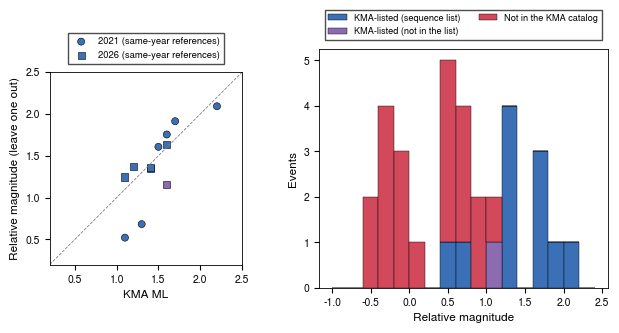

,n,event_id,cls,kma_ml,ml_rel,n_ref,n_amp_sta
0,1,20210718145001,new,NaN,-0.29,6.0,8
1,2,20210719025611,new,NaN,-0.19,6.0,6
2,3,20210719033812,new,NaN,-0.19,6.0,7
3,4,20210720161418,sequence,1.3,0.68,5.0,23
4,5,20210720172705,new,NaN,-0.30,6.0,9
5,6,20210826095443,new,NaN,0.47,6.0,18
6,7,20210826100025,new,NaN,0.07,6.0,9
7,8,20210826101018,new,NaN,-0.24,6.0,6
8,9,20210827002315,sequence,1.6,1.76,5.0,23
9,10,20210827002542,new,NaN,-0.17,6.0,6


In [8]:
def peak(e, net, sta, ts, tp):
    gn, ge = load(e, net, sta, 'N'), load(e, net, sta, 'E')
    if gn is None or ge is None: return None
    n_, e_ = gn[0].copy(), ge[0].copy()
    for tr in (n_, e_): tr.filter('bandpass', freqmin=5, freqmax=20, corners=4, zerophase=True)
    t0 = utc(TIME[e])
    a = n_.slice(t0 + ts - 0.2, t0 + ts + 2.5).data; b = e_.slice(t0 + ts - 0.2, t0 + ts + 2.5).data
    na = n_.slice(t0 + tp - 3.0, t0 + tp - 0.5).data; nb = e_.slice(t0 + tp - 3.0, t0 + tp - 0.5).data
    k = min(len(a), len(b)); kk = min(len(na), len(nb))
    if k < 50 or kk < 50: return None
    amp = float(np.sqrt(a[:k] ** 2 + b[:k] ** 2).max()); noise = float(np.sqrt(na[:kk] ** 2 + nb[:kk] ** 2).max())
    return amp, amp / noise if noise > 0 else np.inf
tt60 = {}
for s in stas[stas.dist_km <= 60].itertuples():
    q = PK[PK.sta == s.Code]
    if q.p.notna().sum() >= 3 and q.s.notna().sum() >= 3: tt60[(s.Network, s.Code)] = (float(q.p.median()), float(q.s.median()))
AMP = {}
for r in E.itertuples():
    for k_, (tp, ts) in tt60.items():
        v = peak(r.event_id, k_[0], k_[1], ts, tp)
        if v and v[1] >= 3: AMP[(r.event_id, k_)] = v[0]
E['year'] = E.time.dt.year
refs = E[E.kma_ml.notna()]
def mrel(e, year):
    est = []
    for rk in refs[refs.year == year].itertuples():
        if rk.event_id == e: continue
        lr = [np.log10(AMP[(e, k_)] / AMP[(rk.event_id, k_)]) for k_ in tt60 if (e, k_) in AMP and (rk.event_id, k_) in AMP]
        if len(lr) >= 2: est.append(rk.kma_ml + float(np.median(lr)))
    return (float(np.median(est)), len(est)) if est else (np.nan, 0)
E = E.drop(columns=[c for c in ('ml_rel', 'n_ref', 'n_amp_sta') if c in E])
E[['ml_rel', 'n_ref']] = [mrel(r.event_id, r.year) for r in E.itertuples()]
E['n_amp_sta'] = [sum((e, k_) in AMP for k_ in tt60) for e in E.event_id]
v = E[E.kma_ml.notna()]; res = v.ml_rel - v.kma_ml
print(f'leave-one-out check on the {len(v)} KMA events (same-year references): relative minus KMA ML: median {res.median():+.2f}, RMS {np.sqrt((res ** 2).mean()):.2f}, max |{res.abs().max():.2f}|')
for y in (2021, 2026):
    rr = res[v.year == y]; print(f'  {y}: n {len(rr)}, median {rr.median():+.2f}, RMS {np.sqrt((rr ** 2).mean()):.2f}')
fig, (ax, bx) = plt.subplots(1, 2, figsize=(7.2, 3.1), gridspec_kw=dict(wspace=0.32, width_ratios=[1, 1.5]))
ax.plot([0.2, 2.5], [0.2, 2.5], color='0.5', lw=0.6, ls='--')
for y, mk in ((2021, 'o'), (2026, 's')):
    s = v[v.year == y]; ax.scatter(s.kma_ml, s.ml_rel, marker=mk, s=26, c=[COL[c] for c in s.cls], edgecolor='k', linewidth=0.4, label=f'{y} (same-year references)')
ax.set_xlabel('KMA ML'); ax.set_ylabel('Relative magnitude (leave one out)'); ax.set_xlim(0.2, 2.5); ax.set_ylim(0.2, 2.5); ax.set_aspect('equal')
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=1, frameon=True, fontsize=6.8)
bins = np.arange(-1.0, 2.6, 0.2)
bx.hist([E[E.cls == c].ml_rel.dropna() for c in ('sequence', 'kma_other', 'new')], bins=bins, stacked=True, color=[COL[c] for c in ('sequence', 'kma_other', 'new')],
        edgecolor='k', linewidth=0.3, label=[LAB[c] for c in ('sequence', 'kma_other', 'new')])
bx.set_xlabel('Relative magnitude'); bx.set_ylabel('Events')
bx.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=True, fontsize=6.6)
save_rep(fig, 'Figure_11_pilot_magnitudes')
plt.show()
display(E[['n', 'event_id', 'cls', 'kma_ml', 'ml_rel', 'n_ref', 'n_amp_sta']].round(2))

## 6. The episodes in time

Each episode on its own time axis, with the processed days shaded. Size is the relative magnitude.

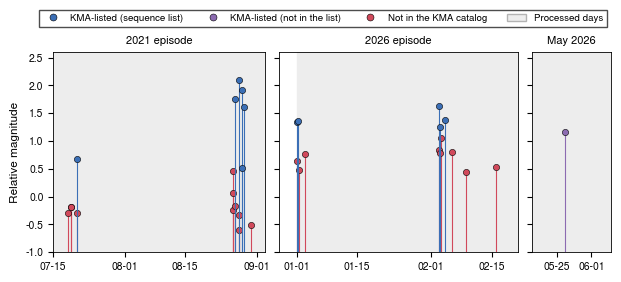

In [9]:
COV = {2021: [(1, 64), (184, 245)], 2026: [(1, 51), (140, 190)]}
spans = [('2021 episode', pd.Timestamp('2021-07-15'), pd.Timestamp('2021-09-03')), ('2026 episode', pd.Timestamp('2025-12-28'), pd.Timestamp('2026-02-21')), ('May 2026', pd.Timestamp('2026-05-20'), pd.Timestamp('2026-06-05'))]
fig, axs = plt.subplots(1, 3, figsize=(7.2, 2.6), sharey=True, gridspec_kw=dict(width_ratios=[1.6, 1.8, 0.6], wspace=0.08))
for ax, (lab, t0, t1) in zip(axs, spans):
    for y, segs in COV.items():
        for a, b in segs:
            s0 = pd.Timestamp(f'{y}-01-01') + pd.Timedelta(days=a - 1); s1 = pd.Timestamp(f'{y}-01-01') + pd.Timedelta(days=b)
            ax.axvspan(max(s0, t0), min(s1, t1), color='0.93', zorder=0) if s1 > t0 and s0 < t1 else None
    s = E[(E.time >= t0) & (E.time <= t1)]
    for c in ('new', 'kma_other', 'sequence'):
        q = s[s.cls == c]; ax.vlines(q.time, -1.0, q.ml_rel, color=COL[c], lw=0.8); ax.plot(q.time, q.ml_rel, 'o', ms=4.5, color=COL[c], mec='k', mew=0.4)
    ax.set_xlim(t0, t1); ax.set_title(lab, fontsize=8)
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=5) if lab != 'May 2026' else mdates.DayLocator(bymonthday=[25, 1])); ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
axs[0].set_ylabel('Relative magnitude'); axs[0].set_ylim(-1.0, 2.6)
handles = [Line2D([], [], marker='o', ls='', ms=5, mfc=COL[c], mec='k', mew=0.4, label=LAB[c]) for c in COL] + [mpl.patches.Patch(fc='0.93', ec='0.7', label='Processed days')]
legend_above(fig, axs, handles, 4, fontsize=7)
save_rep(fig, 'Figure_12_pilot_timeline')
plt.show()

## 7. Record sections of two new events

Stations within 60 km, vertical component, 5–20 Hz, each trace normalized to its own maximum in the window; stations where the event has a P or S pick are drawn dark, the others light (mostly noise for a small event). Ticks: the event's own P and S picks.

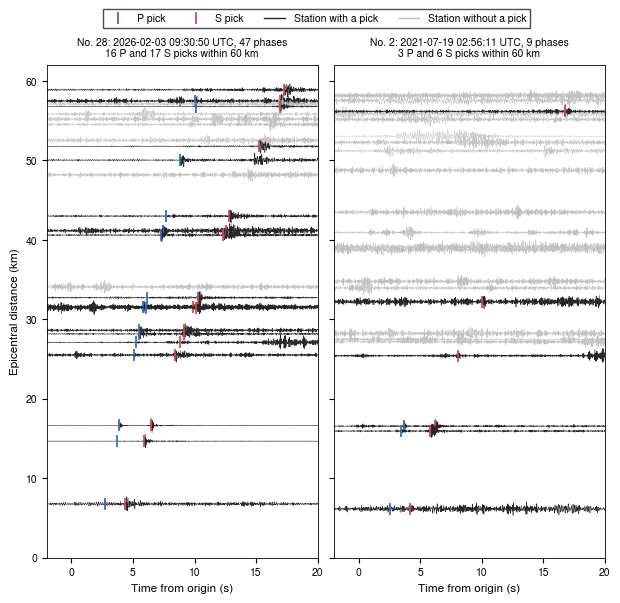

In [10]:
def section(ax, e, title):
    t0 = utc(TIME[e]); n_p = n_s = 0
    for f in sorted(glob.glob(f'{WF}/{e}/{e}.*.??Z.sac')):
        tr = read(f)[0]; h = tr.stats.sac; ref = tr.stats.starttime - h.b; d = float(h.dist)
        if d > 60: continue
        has_p = 'a' in h and h.a > -1e4; has_s = 't0' in h and h.t0 > -1e4
        tr.detrend('demean'); tr.taper(0.05); tr.filter('bandpass', freqmin=5, freqmax=20, corners=4, zerophase=True)
        w = tr.slice(t0 - 2, t0 + 20); x = w.times() + (w.stats.starttime - t0); y = w.data / (np.abs(w.data).max() + 1e-20)
        ax.plot(x, d + 0.9 * y, color='0.15' if (has_p or has_s) else '0.75', lw=0.4 if (has_p or has_s) else 0.3)
        if has_p: ax.plot(ref + float(h.a) - t0, d, '|', color=C_SEQ, ms=9, mew=1.3); n_p += 1
        if has_s: ax.plot(ref + float(h.t0) - t0, d, '|', color=C_NEW, ms=9, mew=1.3); n_s += 1
    ax.set_xlim(-2, 20); ax.set_xlabel('Time from origin (s)'); ax.set_title(f'{title}\n{n_p} P and {n_s} S picks within 60 km', fontsize=7.5)
new = E[E.cls == 'new']
best = new.sort_values('num', ascending=False).iloc[0]; small = new[(new.num <= 12) & (new.dist_km < 1.2)].sort_values('num').iloc[0]
fig, axs = plt.subplots(1, 2, figsize=(7.2, 6.4), sharey=True, gridspec_kw=dict(wspace=0.06))
section(axs[0], best.event_id, f'No. {best.n}: {best.time:%Y-%m-%d %H:%M:%S} UTC, {best.num} phases')
section(axs[1], small.event_id, f'No. {small.n}: {small.time:%Y-%m-%d %H:%M:%S} UTC, {small.num} phases')
axs[0].set_ylabel('Epicentral distance (km)'); axs[0].set_ylim(0, 62)
legend_above(fig, axs, [Line2D([], [], color=C_SEQ, marker='|', ls='', ms=9, mew=1.3, label='P pick'), Line2D([], [], color=C_NEW, marker='|', ls='', ms=9, mew=1.3, label='S pick'),
                        Line2D([], [], color='0.15', lw=1, label='Station with a pick'), Line2D([], [], color='0.75', lw=1, label='Station without a pick')], 4)
plt.show()

## Comprehensive summary

In [11]:
newE = E[E.cls == 'new'].copy()
newE['same_sp'] = (newE.dsp_med.abs() <= 0.1) & (newE.dsp_n >= 2)
newE['above_noise'] = ((newE.cc_P > n95['P']) & (newE.n_cc_P >= 2)) | ((newE.cc_S > n95['S']) & (newE.n_cc_S >= 2))
newE['cc07'] = ((newE.cc_P >= 0.7) & (newE.n_cc_P >= 2)) | ((newE.cc_S >= 0.7) & (newE.n_cc_S >= 2))
odd = newE[~newE.same_sp | ~newE.above_noise]
poor = newE[(newE.num <= 12) | (newE.erz > 1.0)]
S_ = pd.DataFrame([
    ('Events selected', f'{len(E)}: {int((E.cls == "sequence").sum())} on the KMA sequence list, {int((E.cls == "kma_other").sum())} other KMA-listed (' + ', '.join(f'{t:%Y-%m-%d %H:%M} ML {m:.1f}' for t, m in zip(E[E.cls == "kma_other"].time, E[E.cls == "kma_other"].kma_ml)) + f'), {len(newE)} not in the KMA catalog'),
    ('Location quality, KMA-listed', f'median {E[E.cls != "new"].num.median():.0f} phases, gap {E[E.cls != "new"].gap.median():.0f} deg, ERH {E[E.cls != "new"].erh.median():.1f} km, ERZ {E[E.cls != "new"].erz.median():.1f} km'),
    ('Location quality, new', f'median {newE.num.median():.0f} phases, gap {newE.gap.median():.0f} deg, ERH {newE.erh.median():.1f} km, ERZ {newE.erz.median():.1f} km; {len(poor)} with <= 12 phases or ERZ > 1 km'),
    ('Same S-P as the KMA events (within 0.1 s, >= 2 stations)', f'{int(newE.same_sp.sum())} of {len(newE)} new events'),
    ('Correlate with the ML 2.2 above the noise baseline', f'{int(newE.above_noise.sum())} of {len(newE)} (P > {n95["P"]:.2f} or S > {n95["S"]:.2f}, >= 2 stations with signal); at CC >= 0.7: {int(newE.cc07.sum())}'),
    ('Relative magnitude', f'leave-one-out on KMA events: median {res.median():+.2f}, RMS {np.sqrt((res ** 2).mean()):.2f}; new events {newE.ml_rel.min():.1f}-{newE.ml_rel.max():.1f} (median {newE.ml_rel.median():.1f})'),
    ('New events failing a test', ', '.join(f'No. {r.n} ({r.time:%Y-%m-%d %H:%M}: S-P {r.dsp_med:+.2f} s, CC P {r.cc_P:.2f} / S {r.cc_S:.2f})' for r in odd.itertuples()) or 'none'),
], columns=['quantity', 'value']); display(S_)
print('Take-homes:')
print(f'1. The pilot detection finds {len(newE)} events near the patch that KMA did not list, in only part of 2021 and 2026; their relative magnitudes are {newE.ml_rel.min():.1f}-{newE.ml_rel.max():.1f} (median {newE.ml_rel.median():.1f}), below the KMA events.')
print(f'2. {int((newE.same_sp & newE.above_noise).sum())} of them have the KMA events\' S-P intervals and correlate with the ML 2.2 above the noise baseline: they come from the same place. {int(newE.cc07.sum())} already reach the relocation threshold of 0.7 at the median of their stations with signal.')
print(f'3. {len(odd)} fail one of the tests ({", ".join("No. " + str(n) for n in odd.n)}): too weak, overlapping another event, or from elsewhere; the relocation (G5) and template matching (G7) decide them with more stations and stacking.')
r21 = res[v.year == 2021]; small21 = r21[v[v.year == 2021].kma_ml <= 1.3]
print(f'   Caution: the 2021 estimates of the new events rest on {int(newE[newE.year == 2021].n_amp_sta.median())} stations (median), and the leave-one-out check puts the smallest 2021 KMA events {small21.median():+.2f} off, so the 2021 values may be low by about that much.')
print('4. HYPOINVERSE places the events with few phases shallower and up to 1.5 km off the patch even where their S-P intervals match: the absolute locations of small events are poorly constrained, which is what the cross-correlation relocation is for.')
print('5. A KMA-listed event of 26 May 2026 (ML 1.6) lies on the patch three months after the second episode (question Q1); the 11-event sequence list missed it because the KMA catalog used for it ends in March 2026.')

,quantity,value
0,Events selected,"33: 11 on the KMA sequence list, 1 other KMA-listed (202..."
1,"Location quality, KMA-listed","median 84 phases, gap 35 deg, ERH 0.2 km, ERZ 0.3 km"
2,"Location quality, new","median 16 phases, gap 86 deg, ERH 0.5 km, ERZ 0.7 km; 9 ..."
3,"Same S-P as the KMA events (within 0.1 s, >= 2 stations)",20 of 21 new events
4,Correlate with the ML 2.2 above the noise baseline,"19 of 21 (P > 0.46 or S > 0.41, >= 2 stations with signa..."
5,Relative magnitude,"leave-one-out on KMA events: median +0.00, RMS 0.30; new..."
6,New events failing a test,"No. 11 (2021-08-27 02:09: S-P -0.36 s, CC P nan / S nan)..."


Take-homes:
1. The pilot detection finds 21 events near the patch that KMA did not list, in only part of 2021 and 2026; their relative magnitudes are -0.6-1.1 (median 0.3), below the KMA events.
2. 19 of them have the KMA events' S-P intervals and correlate with the ML 2.2 above the noise baseline: they come from the same place. 15 already reach the relocation threshold of 0.7 at the median of their stations with signal.
3. 2 fail one of the tests (No. 11, No. 12): too weak, overlapping another event, or from elsewhere; the relocation (G5) and template matching (G7) decide them with more stations and stacking.
   Caution: the 2021 estimates of the new events rest on 6 stations (median), and the leave-one-out check puts the smallest 2021 KMA events -0.60 off, so the 2021 values may be low by about that much.
4. HYPOINVERSE places the events with few phases shallower and up to 1.5 km off the patch even where their S-P intervals match: the absolute locations of small events are poorly con

## Facts and table for the study-plan report

`docs/reports/study_plan_20261015/facts_pilot.json` and `facts_pilot.tex` (macro definitions `\FactDef{pilot.*}`, read by `report.tex` after `facts.tex` of notebook 90) and `tab_pilot_events.tex` (appendix table of the 33 events).

In [12]:
PF = {}
def tex(v): return str(v).replace('%', r'\%').replace('&', r'\&').replace('_', r'\_').replace('#', r'\#')
def pf(key, value, how=''): PF[f'pilot.{key}'] = dict(value=tex(value), source='notebooks/91_pilot_episode_events.ipynb', how=how)
kmaE = E[E.cls != 'new']
pf('n', len(E)); pf('n_seq', int((E.cls == 'sequence').sum())); pf('n_kmao', int((E.cls == 'kma_other').sum())); pf('n_new', len(newE))
ko = E[E.cls == 'kma_other'].iloc[0]; pf('kmao', f'{ko.time.day} {ko.time:%B %Y}, {ko.time:%H:%M} UTC, ML {ko.kma_ml:.1f}')
pf('q_kma', f'{kmaE.num.median():.0f} phases, a gap of {kmaE.gap.median():.0f}°, ERH {kmaE.erh.median():.1f} km and ERZ {kmaE.erz.median():.1f} km')
pf('q_new', f'{newE.num.median():.0f} phases, a gap of {newE.gap.median():.0f}°, ERH {newE.erh.median():.1f} km and ERZ {newE.erz.median():.1f} km')
pf('n_poor', len(poor)); s1 = E.assign(s1=A.s1).groupby('cls').s1.median(); pf('e1_kma', f'{s1["sequence"]:.2f}'); pf('e1_new', f'{s1["new"]:.2f}')
pf('dd_n', len(DD))
x0_, y0_, z0_ = DD.X.mean(), DD.Y.mean(), DD.Z.mean()
pf('dd_std', f'{(DD.X - x0_).std():.0f} m east, {(DD.Y - y0_).std():.0f} m north and {(DD.Z - z0_).std():.0f} m in depth')
pf('hyp_std', f'{E.x.std() * 1000:.0f} m, {E.y.std() * 1000:.0f} m and {E.depth.std() * 1000:.0f} m')
pf('n_both', int((newE.same_sp & newE.above_noise).sum())); pf('n_samesp', int(newE.same_sp.sum())); pf('n_noise', int(newE.above_noise.sum())); pf('n_cc07', int(newE.cc07.sum()))
pf('noiseP', f'{n95["P"]:.2f}'); pf('noiseS', f'{n95["S"]:.2f}')
pf('fail', ' and '.join(f'No. {r.n} ({r.time:%Y-%m-%d %H:%M})' for r in odd.itertuples()))
pf('loo_rms', f'{np.sqrt((res ** 2).mean()):.2f}')
for y in (2021, 2026): rr = res[v.year == y]; pf(f'loo{y % 100}', f'{np.sqrt((rr ** 2).mean()):.2f}')
pf('ml_new', f'{newE.ml_rel.min():.1f} to {newE.ml_rel.max():.1f}'.replace('-', '−')); pf('ml_new_med', f'{newE.ml_rel.median():.1f}')
pf('low21', f'{abs(small21.median()):.2f}'); pf('n_amp21', int(newE[newE.year == 2021].n_amp_sta.median()))
pre = newE[(newE.time >= '2021-07-18') & (newE.time < '2021-07-20 16:14')]
pf('pre20', ', '.join(f'{t.day} July {t:%H:%M}' for t in pre.time) + ' UTC'); pf('pre20_n', len(pre))
lead_ = (pd.Timestamp('2021-07-20 16:14:18') - pre.time).dt.total_seconds() / 86400; pf('pre20_lead', f'{lead_.min():.1f}–{lead_.max():.1f}')
pf('pre20_sp', f'{pre.dsp_med.abs().max():.2f}'); pf('pre20_cc', f'{pre.cc_S.min():.2f}–{pre.cc_S.max():.2f}')
pre27 = newE[(newE.time >= '2021-08-26') & (newE.time < '2021-08-27')]; pf('pre27', ', '.join(f'{t:%H:%M}' for t in pre27.time) + ' UTC'); pf('pre27_n', len(pre27))
post = newE[newE.time > '2026-02-04 06:00']; pf('post26', ', '.join(f'{t.day}' for t in post.time) + ' February'); pf('post26_n', len(post))
pf('days21', '1–64 and 184–245 (1 January to 5 March and 3 July to 2 September)'); pf('days26', '1–51 and 140–190 (1 January to 20 February and 20 May to 9 July)')
lines = ['% facts_pilot.tex -- written by notebooks/91_pilot_episode_events.ipynb; do not edit by hand.'] + [rf'\FactDef{{{k}}}{{{v["value"]}}}' for k, v in sorted(PF.items())]
open(f'{REP}/facts_pilot.tex', 'w').write('\n'.join(lines) + '\n'); json.dump(PF, open(f'{REP}/facts_pilot.json', 'w'), indent=1, ensure_ascii=False)
SH = {'sequence': 'KMA', 'kma_other': 'KMA*', 'new': 'new'}
fm_ = lambda x, f: '' if pd.isna(x) else f.format(x).replace('-0.00', '0.00').replace('+0.00', '0.00').replace('-', '−')
rows_ = [rf"{r.n} & {r.time:%Y-%m-%d %H:%M:%S} & {r.lat:.4f} & {r.lon:.4f} & {r.depth:.2f} & {r.num} & {r.gap} & {r.erh:.1f} & {r.erz:.1f} & {fm_(r.dsp_med, '{:+.2f}')} & {fm_(r.cc_S, '{:.2f}')} & {fm_(r.ml_rel, '{:.1f}')} & {fm_(r.kma_ml, '{:.1f}')} & {SH[r.cls]} \\" for r in E.itertuples()]
head_ = [r'\begin{longtable}{@{}rlrrrrrrrrrrrl@{}}', r'\toprule', r'No. & Origin (UTC) & Lat. & Lon. & Depth & Ph. & Gap & ERH & ERZ & $\Delta$(S$-$P) & CC$_\mathrm{S}$ & Rel. M & KMA ML & Class \\',
         r' & & (°N) & (°E) & (km) & & (°) & (km) & (km) & (s) & & & & \\', r'\midrule', r'\endhead']
open(f'{REP}/tab_pilot_events.tex', 'w').write('% written by notebooks/91_pilot_episode_events.ipynb; do not edit by hand\n' + '\n'.join(head_ + rows_ + [r'\bottomrule', r'\end{longtable}']) + '\n')
print(f'{len(PF)} pilot facts -> facts_pilot.tex; {len(rows_)} rows -> tab_pilot_events.tex; report figures:', sorted(os.path.basename(f) for f in glob.glob(f'{RFIG}/Figure_*pilot*.pdf')))

38 pilot facts -> facts_pilot.tex; 33 rows -> tab_pilot_events.tex; report figures: ['Figure_07_pilot_locations_relative.pdf', 'Figure_08_pilot_locations_absolute.pdf', 'Figure_09_pilot_waveforms.pdf', 'Figure_10_pilot_same_patch.pdf', 'Figure_11_pilot_magnitudes.pdf', 'Figure_12_pilot_timeline.pdf']
